# Pneumonia Multimodal Observation Demo

This notebook starts from the numeric pneumonia state sequence, maps it to observation vectors, and decodes each state into multimodal images.

In [1]:
import csv
import os
import sys
from pathlib import Path

from IPython.display import Image as IPyImage, display
from PIL import Image as PILImage, ImageDraw

try:
    current_dir = Path(__file__).resolve().parent
except NameError:
    current_dir = Path.cwd().resolve()

project_root = current_dir
while project_root != project_root.parent and not (project_root / "Patient").exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from Patient.models.pneumonia_model import PneumoniaStateTransitionModel
from Patient.phenotype_decoders.multi_decoder import multi_decoder
from Patient.phenotype_decoders.generate_observation_sequence import observe_state_sequence

In [2]:
model = PneumoniaStateTransitionModel()
NO = model.NO_INTERVENTION
A = model.ANTIBIOTIC_A
B = model.ANTIBIOTIC_B

actions = [NO] * 2 + [A] * model.model_params["p"] + [B] * model.model_params["v"]
result = model.simulate(actions, initial_state=model.SEVERE, return_details=True)
states = result["states"]
events = result["events"]
observations = observe_state_sequence(states, seed=2026)

print(f"time steps: {len(states)}")
print(f"final state: {model.state_name(states[-1])}")

time steps: 13
final state: healthy


In [3]:
action_at_time = [NO] + actions
event_at_time = ["initial"] + [event.value for event in events]
rows = []
for t, (action, state, event, observation) in enumerate(zip(action_at_time, states, event_at_time, observations)):
    rows.append({
        "timestamp": t,
        "action": model.action_name(action),
        "state": model.state_name(state),
        "event": event,
        "o1": float(observation[0]),
        "o2": float(observation[1]),
        "o3": float(observation[2]),
    })

try:
    import pandas as pd
    display(pd.DataFrame(rows))
except ImportError:
    for row in rows:
        print(row)

,timestamp,action,state,event,o1,o2,o3
0,0,none,severe,initial,0.000000,0.028831,0.971169
1,1,none,severe,state_maintenance,0.118870,0.054360,0.826770
2,2,none,severe,state_maintenance,0.000000,0.030274,0.969726
3,3,antibiotic_A,severe,state_maintenance,0.000000,0.064093,0.935907
4,4,antibiotic_A,severe,state_maintenance,0.000000,0.000000,1.000000
5,5,antibiotic_A,severe,state_maintenance,0.000000,0.000000,1.000000
6,6,antibiotic_A,mild,partial_transition,0.000000,1.000000,0.000000
7,7,antibiotic_B,mild,state_maintenance,0.062989,0.937011,0.000000
8,8,antibiotic_B,mild,state_maintenance,0.051485,0.948515,0.000000
9,9,antibiotic_B,mild,state_maintenance,0.130981,0.852020,0.016999


In [4]:
output_dir = (
    project_root
    / "Patient"
    / "phenotype_decoders"
    / "observation_data"
    / "generated_observations"
    / "demo_pneumonia"
)
output_dir.mkdir(parents=True, exist_ok=True)
csv_path = output_dir / "observation_sequence.csv"

with csv_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=["timestamp", "action", "state", "event", "o1", "o2", "o3"])
    writer.writeheader()
    writer.writerows(rows)

print(f"saved {csv_path}")

saved E:\iHP-9.3\iHP-10.11\Patient\phenotype_decoders\observation_data\generated_observations\demo_pneumonia\observation_sequence.csv


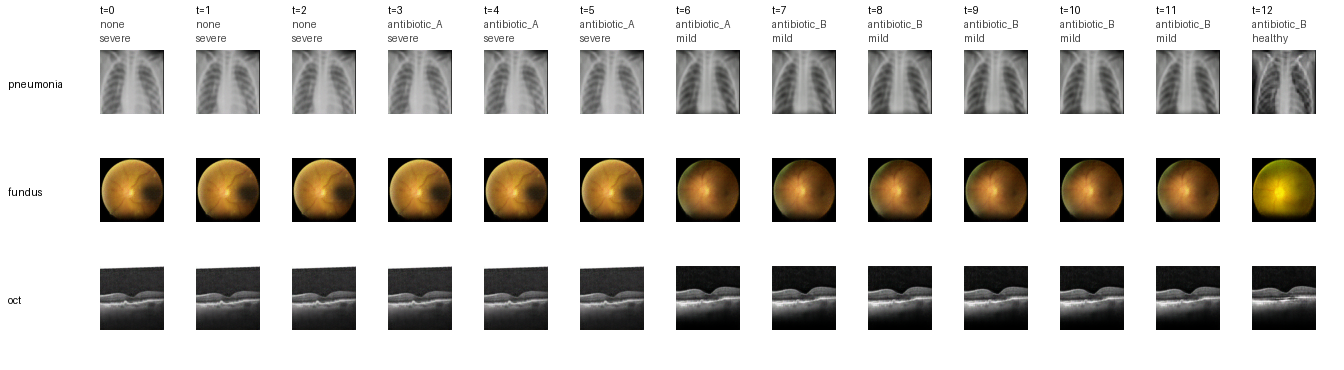

saved E:\iHP-9.3\iHP-10.11\Patient\phenotype_decoders\observation_data\generated_observations\demo_pneumonia\multimodal_sequence.png


In [5]:
modalities = ("pneumonia", "fundus", "oct")
decoded_frames = [multi_decoder(state) for state in states]

image_w, image_h = decoded_frames[0][0].size
cell_w = max(96, image_w + 24)
cell_h = image_h + 44
left_margin = 96
top_margin = 46
canvas = PILImage.new("RGB", (left_margin + cell_w * len(states), top_margin + cell_h * len(modalities)), "white")
draw = ImageDraw.Draw(canvas)

for col, (state, action) in enumerate(zip(states, action_at_time)):
    x = left_margin + col * cell_w
    draw.text((x + 4, 4), f"t={col}", fill=(0, 0, 0))
    draw.text((x + 4, 18), model.action_name(action), fill=(70, 70, 70))
    draw.text((x + 4, 32), model.state_name(state), fill=(70, 70, 70))

for row, modality in enumerate(modalities):
    y = top_margin + row * cell_h
    draw.text((8, y + image_h // 2), modality, fill=(0, 0, 0))
    for col, images in enumerate(decoded_frames):
        x = left_margin + col * cell_w
        canvas.paste(images[row], (x + 4, y + 4))

image_path = output_dir / "multimodal_sequence.png"
canvas.save(image_path)
display(IPyImage(filename=str(image_path)))
print(f"saved {image_path}")